# BulkFormer vs PCA: blood transcriptome classification
Bushra Rashrash · Michigan AI Symposium 2026

Two cohorts are analysed separately: GSE251778 (80 MDD, 89 controls; leukocytes) and GSE289146 (229 affected, 70 controls; PBMCs, broader psychiatric phenotype).

Run in Google Colab from top to bottom. CPU is sufficient; repeated nested CV can take substantial time. The final cell exports results. Enable Drive below to retain checkpoints between sessions.

Saved BulkFormer embeddings and original predictions are embedded in this notebook. The neural encoder is not rerun. Public expression inputs are downloaded for PCA and preprocessing checks. Saved outputs below come from the supplied executed notebook; this editorial revision has not rerun the analyses.

The five repeats reuse participants. Bootstrap intervals condition on fixed predictions and omit retraining uncertainty. Sex analyses are exploratory; no external validation or causal analysis is included.

**Public release:** saved statistical outputs are from the supplied executed notebook; no statistical rerun was performed during packaging. The embedded participant-level input archive is withheld pending faculty sign-off. The loader below now reads a separately supplied local archive and has not been rerun. Other statistical code is unchanged.


## Analysis settings
Five matched repeats use 5 outer and 4 inner folds. Separate-sex models use 4 outer and 3 inner folds. Inner CV selects ridge C; PCA retains 90% of training variance. Historical values are retained separately for provenance.

In [ ]:
# Configuration — defaults run all requested analyses for both cohorts.
from pathlib import Path
RUN_FULL_ANALYSES = True  # False: original-prediction bootstrap only, without expression downloads.
USE_GOOGLE_DRIVE = False  # True: prompts you to mount your Drive for persistent checkpoints.
N_BOOTSTRAP = 5000
BOOTSTRAP_SEED = 20261009
REPEAT_SEEDS = [20260921, 20260922, 20260923, 20260924, 20260925]
C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]

# Explicit reconstruction choice, NOT a verified record of the earlier extended model.
# Baseline age/BMI/sex is always included. Review these extra variables with Dr. Zhou.
MDD_EXTENDED_COVARIATES = ['RIN', 'Polynuclear_neutrophile', 'Lymphocyte']

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/BulkFormer_Poster_Additional_Analyses')
else:
    ROOT = Path('/content/BulkFormer_Poster_Additional_Analyses')
ROOT.mkdir(parents=True, exist_ok=True)
INPUTS = ROOT / 'original_saved_results'
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
CHECKPOINTS = ROOT / 'checkpoints'
for folder in [INPUTS, DATA, RESULTS, FIGURES, CHECKPOINTS]: folder.mkdir(parents=True, exist_ok=True)
print('Working folder:', ROOT)
print('Five-repeat seeds:', REPEAT_SEEDS)
print('Full analysis:', RUN_FULL_ANALYSES)


Working folder: /content/BulkFormer_Poster_Additional_Analyses
Five-repeat seeds: [20260921, 20260922, 20260923, 20260924, 20260925]
Full analysis: True


In [ ]:
# Install the tested sklearn version and small supporting packages; no GPU dependencies.
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'scikit-learn==1.8.0', 'rdata==1.1.0', 'requests', 'matplotlib', 'pandas', 'numpy', 'tqdm'])
import io, os, json, base64, zipfile, hashlib, platform, importlib.metadata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False,
                     'pdf.fonttype': 42, 'savefig.dpi': 300})
print('scikit-learn:', importlib.metadata.version('scikit-learn'))


scikit-learn: 1.8.0


## 1. Load saved embeddings and predictions

This public notebook requires the original saved-input ZIP from the project team. It is not included pending faculty sign-off on participant-level sharing. Set `ORIGINAL_ARCHIVE_PATH` below to that ZIP. Its SHA-256 must match the original archive. No embeddings are regenerated.


In [ ]:
ORIGINAL_ARCHIVE_SHA256 = 'cc233d28eac90e0e635618a61ffde2b11a678bdeb741349192ef1d50a4a672f1'
# Supply this file locally; do not commit it to the public repository.
ORIGINAL_ARCHIVE_PATH = Path('/content/BulkFormer_original_saved_inputs.zip')
if not ORIGINAL_ARCHIVE_PATH.is_file():
    raise FileNotFoundError(
        'Original saved-input archive is not distributed with this public notebook. '
        'Obtain the approved archive from the project team and set ORIGINAL_ARCHIVE_PATH.'
    )
archive_bytes = ORIGINAL_ARCHIVE_PATH.read_bytes()
assert hashlib.sha256(archive_bytes).hexdigest() == ORIGINAL_ARCHIVE_SHA256
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    for member in archive.infolist():
        destination = (INPUTS / member.filename).resolve()
        if not destination.is_relative_to(INPUTS.resolve()): raise ValueError('Unsafe archive path')
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(member))
original = {}
for cohort in ['GSE251778', 'GSE289146']:
    folder = INPUTS / cohort
    predictions = pd.read_csv(folder / 'out_of_fold_predictions.csv', dtype={'sample_id': str})
    label = 'MDD' if cohort == 'GSE251778' else 'Affected'
    assert predictions['sample_id'].is_unique
    emb = np.load(folder / 'bulkformer_37M_mean_embeddings.npy', allow_pickle=False)
    assert emb.shape == (len(predictions), 131)
    original[cohort] = {'predictions': predictions, 'embeddings': emb,
                        'label': label, 'sample_ids': predictions['sample_id'].to_numpy()}
    print(cohort, 'participants:', len(predictions), '| embedding shape:', emb.shape)


## 2. Evaluation functions
Imputation, scaling, encoding and PCA are fitted within training folds. Methods use matched partitions. BulkFormer features contain 128 learned dimensions and three expression summaries.

In [ ]:
import hashlib, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from threadpoolctl import threadpool_limits

def paired_bootstrap(y, pca, bf, n_boot=5000, seed=20261009):
    """Stratified participant bootstrap, paired methods, fixed OOF predictions.
    Does not refit models or account for training-set uncertainty.
    """
    y = np.asarray(y, dtype=int)
    pca, bf = np.asarray(pca, float), np.asarray(bf, float)
    if set(y) != {0, 1} or not (len(y) == len(pca) == len(bf)):
        raise ValueError('Bootstrap requires aligned predictions and two classes.')
    if not np.isfinite(np.c_[pca, bf]).all():
        raise ValueError('Nonfinite predictions.')
    rng = np.random.default_rng(seed)
    strata = [np.flatnonzero(y == label) for label in (0, 1)]
    draws = np.empty((n_boot, 3))
    for b in range(n_boot):
        ix = np.concatenate([rng.choice(s, size=len(s), replace=True) for s in strata])
        a, c = roc_auc_score(y[ix], pca[ix]), roc_auc_score(y[ix], bf[ix])
        draws[b] = [a, c, c-a]
    a, c = roc_auc_score(y, pca), roc_auc_score(y, bf)
    limits = np.quantile(draws, [0.025, 0.975], axis=0)
    return pd.DataFrame({'comparison': ['PCA', 'BulkFormer', 'BF_minus_PCA'],
        'estimate': [a, c, c-a], 'lower95': limits[0], 'upper95': limits[1],
        'n': len(y), 'n_boot': n_boot, 'bootstrap_seed': seed,
        'interval_type': 'conditional_paired_stratified_percentile'})

def numeric_model(cache=None, use_pca=False):
    steps = []
    if use_pca:
        steps.append(('pca', PCA(n_components=0.90, svd_solver='full')))
    steps.extend([('scale', StandardScaler()),
        ('ridge', LogisticRegression(C=1, l1_ratio=0.0, solver='liblinear',
          max_iter=5000, class_weight='balanced', random_state=20260921))])
    return Pipeline(steps, memory=str(cache) if cache and use_pca else None)

def covariate_model(frame, numeric, categorical):
    transformers = []
    if numeric:
        transformers.append(('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler())]), numeric))
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical))
    return Pipeline([('preprocess', ColumnTransformer(transformers, remainder='drop')),
        ('ridge', LogisticRegression(l1_ratio=0.0, solver='liblinear', max_iter=5000,
          class_weight='balanced', random_state=20260921))])

def model_specs(data, cache, extended_covariates=None):
    Xp, Xb, meta = data['expression'], data['embeddings'], data['metadata']
    if Xb.shape[1] != 131:
        raise ValueError('Expected 131 features: 128 learned followed by 3 summaries.')
    specs = {
        'PCA': (Xp, numeric_model(cache, True)),
        'full131': (Xb, numeric_model()),
        'learned128': (Xb[:, :128], numeric_model()),
        'summaries3': (Xb[:, 128:], numeric_model())}
    groups = {'age_BMI_sex': ['age', 'bmi', 'sex']}
    if extended_covariates:
        groups['extended_covariates'] = list(dict.fromkeys(groups['age_BMI_sex'] + extended_covariates))
    for name, cols in groups.items():
        absent = [c for c in cols if c not in meta.columns]
        if absent:
            raise ValueError(f'{name}: missing covariates {absent}; check explicit configuration.')
        cov = meta[cols].copy().reset_index(drop=True)
        categorical = [c for c in cols if c == 'sex' or not pd.api.types.is_numeric_dtype(cov[c])]
        numeric = [c for c in cols if c not in categorical]
        for c in categorical:
            cov[c] = cov[c].astype(object).where(cov[c].notna(), np.nan)
        specs[name] = (cov, covariate_model(cov, numeric, categorical))
        feature_names = [f'bf_{j:03d}' for j in range(Xb.shape[1])]
        combined = pd.concat([pd.DataFrame(Xb, columns=feature_names), cov], axis=1)
        specs['BF_plus_' + name] = (combined, covariate_model(combined, feature_names+numeric, categorical))
    return specs

def subset_rows(X, rows):
    return X.iloc[rows] if isinstance(X, pd.DataFrame) else X[rows]

def nested_evaluate(data, specs, seeds, output_dir, outer_folds=5, inner_folds=4,
                    inner_offset=1, c_values=(0.001, 0.01, 0.1, 1, 10, 100)):
    """Matched outer AND inner partitions. Preprocessing fitted inside inner CV.
    Checkpoint each method/repeat; cache key includes data, options and estimators.
    """
    output_dir = Path(output_dir); output_dir.mkdir(parents=True, exist_ok=True)
    y = np.asarray(data['y'], int); ids = np.asarray(data['sample_ids']).astype(str)
    if len(set(ids)) != len(ids) or set(y) != {0, 1}:
        raise ValueError('Unique participant IDs and binary outcomes are required.')
    if np.bincount(y).min() < outer_folds:
        raise ValueError('Too few participants in one class for the outer folds.')
    all_scores, all_predictions, all_folds = [], [], []
    from joblib import hash as joblib_hash
    for method, (X, pipe) in specs.items():
        if len(X) != len(y):
            raise ValueError(f'{method}: input row count mismatch.')
        signature = joblib_hash((X, y, ids, pipe.get_params(), tuple(c_values), outer_folds, inner_folds, inner_offset))
        for repeat, seed in enumerate(seeds, 1):
            stem = output_dir / f'{method}_seed{seed}_{signature[:12]}'
            paths = [Path(str(stem)+s) for s in ('_score.csv', '_predictions.csv', '_folds.csv')]
            if all(p.exists() for p in paths):
                score, pred, folds = [pd.read_csv(p) for p in paths]
                print('Reused', data['name'], method, seed, flush=True)
            else:
                outer = list(StratifiedKFold(outer_folds, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))
                probabilities = np.full(len(y), np.nan); fold_ids = np.zeros(len(y), int)
                fold_records = []
                for fold, (train, test) in enumerate(outer, 1):
                    k = min(inner_folds, int(np.bincount(y[train], minlength=2).min()))
                    if k < 2: raise ValueError('Too few training samples for inner CV.')
                    inner = list(StratifiedKFold(k, shuffle=True, random_state=seed+inner_offset).split(np.zeros(len(train)), y[train]))
                    search = GridSearchCV(clone(pipe), {'ridge__C': list(c_values)},
                        scoring='roc_auc', cv=inner, n_jobs=1, refit=True, error_score='raise')
                    with threadpool_limits(limits=2):
                        search.fit(subset_rows(X, train), y[train])
                        p = search.predict_proba(subset_rows(X, test))[:, 1]
                    probabilities[test] = p; fold_ids[test] = fold
                    fold_records.append({'cohort': data['name'], 'method': method, 'repeat': repeat,
                        'seed': seed, 'fold': fold, 'AUROC': roc_auc_score(y[test], p),
                        'best_C': search.best_params_['ridge__C'], 'n_train': len(train), 'n_test': len(test),
                        'n_PCs': getattr(search.best_estimator_.named_steps.get('pca'), 'n_components_', np.nan)})
                    print(f"{data['name']} | {method} | repeat {repeat}/{len(seeds)} | fold {fold}/{outer_folds}", flush=True)
                assert np.isfinite(probabilities).all()
                score = pd.DataFrame([{'cohort': data['name'], 'method': method, 'repeat': repeat,
                    'seed': seed, 'AUROC': roc_auc_score(y, probabilities),
                    'AUPRC': average_precision_score(y, probabilities),
                    'balanced_accuracy': balanced_accuracy_score(y, probabilities >= 0.5),
                    'prevalence': y.mean(), 'n': len(y)}])
                pred = pd.DataFrame({'cohort': data['name'], 'method': method, 'repeat': repeat,
                    'seed': seed, 'sample_id': ids, 'y': y, 'probability': probabilities, 'fold': fold_ids})
                folds = pd.DataFrame(fold_records)
                for table, p in zip([score, pred, folds], paths): table.to_csv(p, index=False)
            all_scores.append(score); all_predictions.append(pred); all_folds.append(folds)
    return tuple(pd.concat(items, ignore_index=True) for items in (all_scores, all_predictions, all_folds))

def validate_cohort(data):
    n = len(data['sample_ids'])
    assert data['expression'].shape[0] == data['embeddings'].shape[0] == len(data['metadata']) == len(data['y']) == n
    assert list(data['metadata'].index.astype(str)) == list(data['sample_ids'])
    assert set(data['y']) == {0, 1}
    assert np.isfinite(data['expression']).all() and np.isfinite(data['embeddings']).all()
    assert data['embeddings'].shape[1] == 131
    assert len(set(data['sample_ids'])) == n
    if (data['expression'] < 0).any(): raise ValueError('Negative log-TPM in PCA inputs.')
    return {'cohort': data['name'], 'n': n, 'positive': int(np.sum(data['y'])),
        'negative': int(n-np.sum(data['y'])), 'genes': data['expression'].shape[1], 'features': 131}


## 3. Original-prediction bootstrap
Use 5,000 paired, class-stratified participant resamples and percentile intervals. Models are not refitted. An interval crossing zero does not establish equivalence.

In [ ]:
original_intervals = []
for cohort, item in original.items():
    p = item['predictions']
    table = paired_bootstrap(p[item['label']], p['PCA_oof_probability'],
                             p['BulkFormer_oof_probability'], N_BOOTSTRAP, BOOTSTRAP_SEED)
    table.insert(0, 'cohort', cohort)
    original_intervals.append(table)
original_intervals = pd.concat(original_intervals, ignore_index=True)
original_intervals.to_csv(RESULTS / 'original_conditional_bootstrap.csv', index=False)
display(original_intervals.round(4))


,cohort,comparison,estimate,lower95,upper95,n,n_boot,bootstrap_seed,interval_type
0,GSE251778,PCA,0.7900,0.7138,0.8566,169,5000,20261009,conditional_paired_stratified_percentile
1,GSE251778,BulkFormer,0.7584,0.6831,0.8271,169,5000,20261009,conditional_paired_stratified_percentile
2,GSE251778,BF_minus_PCA,-0.0316,-0.1076,0.0445,169,5000,20261009,conditional_paired_stratified_percentile
3,GSE289146,PCA,0.6013,0.5224,0.6759,299,5000,20261009,conditional_paired_stratified_percentile
4,GSE289146,BulkFormer,0.5846,0.5075,0.6621,299,5000,20261009,conditional_paired_stratified_percentile
5,GSE289146,BF_minus_PCA,-0.0167,-0.1043,0.0701,299,5000,20261009,conditional_paired_stratified_percentile


## 4. Expression inputs and covariates
GSE289146: use RSEM TPM, remove Ensembl version suffixes, sum duplicate IDs, then apply ln(TPM + 1) once. This is not the publication's corrected log2CPM matrix.

GSE251778: convert author-supplied counts to TPM using the pinned gene-length table, then apply ln(TPM + 1). Unmatched lengths retain the original 1,000-bp fallback; the audit counts them. This is a preprocessing limitation. Changing the conversion requires a separate sensitivity analysis and regenerated embeddings.

Saved embeddings are not log-transformed again. Downloads and reconstructed inputs are cached.

In [ ]:
import requests, time, re
from concurrent.futures import ThreadPoolExecutor, as_completed

BF_COMMIT = '5bcf5b99e799cd55f41e4d6fe8200b2cdf3d9589'
MDD_COMMIT = '1d51753c1cfe444bbb14ee989fbaf5739ac39483'
BF_RAW = f'https://raw.githubusercontent.com/KangBoming/BulkFormer/{BF_COMMIT}/data/'

def download(url, destination, legacy=None):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 0: return destination
    if legacy and Path(legacy).is_file(): return Path(legacy)
    destination.parent.mkdir(parents=True, exist_ok=True)
    url = re.sub(r'^ftp://ftp\.ncbi\.nlm\.nih\.gov/', 'https://ftp.ncbi.nlm.nih.gov/', str(url))
    for attempt in range(4):
        try:
            temporary = destination.with_suffix(destination.suffix + '.part')
            with requests.get(url, stream=True, timeout=(30, 180)) as response:
                response.raise_for_status()
                with temporary.open('wb') as handle:
                    for chunk in response.iter_content(1024*1024):
                        if chunk: handle.write(chunk)
            temporary.replace(destination)
            return destination
        except Exception:
            if attempt == 3: raise
            time.sleep(2 ** attempt)

datasets = {}; normalization_audit = []
if RUN_FULL_ANALYSES:
    vocab_path = download(BF_RAW+'bulkformer_gene_info.csv', DATA/'bulkformer_gene_info.csv')
    vocabulary = pd.read_csv(vocab_path)['ensg_id'].astype(str).tolist()
    assert len(vocabulary) == 20010 and len(set(vocabulary)) == 20010
    print('Gene vocabulary loaded.')
else:
    print('Quick mode: expression rebuilding and model refitting will be skipped.')


Gene vocabulary loaded.


In [ ]:
# Primary MDD cohort
if RUN_FULL_ANALYSES:
    import rdata
    rds_path = download(
        f'https://raw.githubusercontent.com/INSERM-U1141-Neurodiderot/multiomics_MDD/{MDD_COMMIT}/1_Single_Omics/data.mRNA.rds',
        DATA/'data.mRNA.rds', '/content/mdd_bulkformer_comparison/multiomics_MDD/1_Single_Omics/data.mRNA.rds')
    rds = rdata.read_rds(rds_path)
    counts = pd.concat([rds['raw.data.Male'], rds['raw.data.Female']], axis=1).T.astype(np.float32)
    parts = []
    for sex in ['Male', 'Female']:
        frame = rds['cov.'+sex].copy(); frame['sex'] = sex; parts.append(frame)
    meta = pd.concat(parts).loc[counts.index].rename(columns={'Age':'age', 'BMI':'bmi'})
    ids = original['GSE251778']['sample_ids']
    counts.index = counts.index.astype(str); meta.index = meta.index.astype(str)
    assert set(ids) == set(counts.index) == set(meta.index)
    counts, meta = counts.loc[ids], meta.loc[ids]
    y = (meta['Group'] == 'Patient').to_numpy(dtype=int)
    np.testing.assert_array_equal(y, original['GSE251778']['predictions']['MDD'])
    np.testing.assert_array_equal(meta['sex'], original['GSE251778']['predictions']['Sex'])
    assert counts.shape == (169, 52237) and y.sum() == 80
    assert np.isfinite(counts.to_numpy()).all() and (counts.to_numpy() >= 0).all()
    length_path = download(BF_RAW+'gene_length_df.csv', DATA/'gene_length_df.csv')
    length_lookup = pd.read_csv(length_path).set_index('ensg_id')['length'].to_dict()
    observed = [g for g in vocabulary if g in counts.columns]
    length_matched = np.array([g in length_lookup for g in counts.columns])
    lengths_kb = np.array([length_lookup.get(g, 1000.0)/1000.0 for g in counts.columns])
    assert np.isfinite(lengths_kb).all() and (lengths_kb > 0).all()
    cache = DATA/'GSE251778_log_tpm_original.npz'
    if cache.exists():
        with np.load(cache, allow_pickle=False) as z:
            np.testing.assert_array_equal(z['ids'], ids)
            np.testing.assert_array_equal(z['genes'], np.asarray(observed))
            expression = z['expression']
    else:
        rate = counts.to_numpy(dtype=np.float64)/lengths_kb[None,:]
        denominator = rate.sum(axis=1, keepdims=True)
        assert (denominator > 0).all()
        log_tpm = pd.DataFrame(np.log1p(rate/denominator*1e6).astype(np.float32), index=ids, columns=counts.columns)
        expression = log_tpm[observed].to_numpy()
        np.savez_compressed(cache, expression=expression, ids=np.asarray(ids,dtype=str), genes=np.asarray(observed,dtype=str))
        del rate, log_tpm
    datasets['GSE251778'] = dict(name='GSE251778', sample_ids=ids, y=y,
        expression=expression, embeddings=original['GSE251778']['embeddings'], metadata=meta)
    normalization_audit.append(dict(cohort='GSE251778', input='author RDS raw counts',
        transform='counts / length; TPM; ln(TPM+1)', observed_genes=len(observed),
        padded_genes=20010-len(observed), length_matched=int(length_matched.sum()),
        fallback_1000bp=int((~length_matched).sum()), covariate_corrected_expression=False))
    print('MDD expression:', expression.shape, '| fallback gene lengths:', (~length_matched).sum())
    del counts, rds


MDD expression: (169, 19271) | fallback gene lengths: 1291


In [ ]:
# Exploratory PBMC cohort
if RUN_FULL_ANALYSES:
    ids = original['GSE289146']['sample_ids']
    meta = pd.read_csv(INPUTS/'GSE289146'/'verified_sample_metadata.csv', index_col='sample_id').loc[ids]
    y = meta['Affected'].to_numpy(dtype=int)
    np.testing.assert_array_equal(y, original['GSE289146']['predictions']['Affected'])
    assert len(meta) == 299 and y.sum() == 229
    cache = DATA/'GSE289146_log_tpm_original.npz'
    if cache.exists():
        with np.load(cache, allow_pickle=False) as z:
            np.testing.assert_array_equal(z['ids'], ids)
            expression, observed = z['expression'], z['genes'].tolist()
    else:
        def get_sample(sample_id):
            return sample_id, download(meta.loc[sample_id,'gene_url'], DATA/'rsem'/f'{sample_id}.genes.results.gz',
                f'/content/gse289146_bulkformer_comparison/rsem_gene_files/{sample_id}.genes.results.gz')
        paths = {}
        with ThreadPoolExecutor(max_workers=6) as pool:
            futures = [pool.submit(get_sample, sample_id) for sample_id in ids]
            for future in tqdm(as_completed(futures), total=len(ids), desc='RSEM downloads'):
                sample_id, p = future.result(); paths[sample_id] = p
        rows = []
        for sample_id in tqdm(ids, desc='Read TPM'):
            frame = pd.read_csv(paths[sample_id], sep='\t', usecols=['gene_id','TPM'])
            assert np.isfinite(frame['TPM']).all() and (frame['TPM'] >= 0).all()
            frame['gene_id'] = frame['gene_id'].astype(str).str.replace(r'\.\d+$','',regex=True)
            rows.append(frame.groupby('gene_id',sort=False)['TPM'].sum().reindex(vocabulary).rename(sample_id))
        aligned = pd.DataFrame(rows, index=ids).astype(np.float32)
        observed = aligned.columns[aligned.notna().any(axis=0)].tolist()
        expression = np.log1p(aligned[observed].fillna(0.0)).to_numpy(dtype=np.float32)
        np.savez_compressed(cache, expression=expression, ids=np.asarray(ids,dtype=str), genes=np.asarray(observed,dtype=str))
        del rows, aligned
    assert expression.shape == (299,19894)
    datasets['GSE289146'] = dict(name='GSE289146', sample_ids=ids, y=y,
        expression=expression, embeddings=original['GSE289146']['embeddings'], metadata=meta)
    normalization_audit.append(dict(cohort='GSE289146', input='RSEM TPM column', transform='ln(TPM+1) once',
        observed_genes=len(observed), padded_genes=20010-len(observed),
        length_matched=None, fallback_1000bp=None, covariate_corrected_expression=False))
    print('PBMC expression:', expression.shape)


RSEM downloads:   0%|          | 0/299 [00:00<?, ?it/s]

Read TPM:   0%|          | 0/299 [00:00<?, ?it/s]

PBMC expression: (299, 19894)


## 5. Alignment and preprocessing checks
Compare sample order and the three saved expression summaries with reconstructed inputs, allowing for float16 precision. These checks do not validate the encoder weights or graph implementation.

In [ ]:
if RUN_FULL_ANALYSES:
    audit_rows=[]
    for cohort,d in datasets.items():
        audit_rows.append(validate_cohort(d))
        X = d['expression']; missing = 20010-X.shape[1]
        expected = np.column_stack([np.full(len(X),missing/20010), X.mean(axis=1),
                                     ((X!=0).sum(axis=1)+missing)/20010])
        np.testing.assert_allclose(d['embeddings'][:,128:], expected, rtol=0.005, atol=0.003,
            err_msg=f'{cohort}: original summary features do not match rebuilt input; stop and inspect.')
        print(cohort, 'alignment and summary features verified.')
        d['metadata'].to_csv(RESULTS/f'{cohort}_metadata.csv')
    audit_table=pd.DataFrame(audit_rows)
    normalization_table=pd.DataFrame(normalization_audit)
    audit_table.to_csv(RESULTS/'cohort_audit.csv',index=False)
    normalization_table.to_csv(RESULTS/'normalization_audit.csv',index=False)
    display(audit_table); display(normalization_table)


GSE251778 alignment and summary features verified.
GSE289146 alignment and summary features verified.


,cohort,n,positive,negative,genes,features
0,GSE251778,169,80,89,19271,131
1,GSE289146,299,229,70,19894,131


,cohort,input,transform,observed_genes,padded_genes,length_matched,fallback_1000bp,covariate_corrected_expression
0,GSE251778,author RDS raw counts,counts / length; TPM; ln(TPM+1),19271,739,50946.0,1291.0,False
1,GSE289146,RSEM TPM column,ln(TPM+1) once,19894,116,NaN,NaN,False


## 6. Repeated CV and sensitivity analyses
Compare PCA, all 131 BulkFormer features, 128 learned features, three summaries, covariates alone, and features plus covariates. All methods use matched folds within each repeat. The extended MDD covariate list is a documented reconstruction, not a verified historical specification.

In [ ]:
for cohort, data in datasets.items():
    data["metadata"].columns = pd.Index(
        [str(column) for column in data["metadata"].columns],
        dtype=object
    )

print("Column names fixed. Rerun the failed analysis cell.")

Column names fixed. Rerun the failed analysis cell.


In [ ]:
repeat_scores=[]; repeat_predictions=[]; fold_tables=[]
if RUN_FULL_ANALYSES:
    for cohort,d in datasets.items():
        extended = MDD_EXTENDED_COVARIATES if cohort=='GSE251778' else None
        specs = model_specs(d, ROOT/'pca_cache'/cohort, extended)
        scores,predictions,folds=nested_evaluate(d,specs,REPEAT_SEEDS,CHECKPOINTS/cohort/'pooled',c_values=C_VALUES)
        repeat_scores.append(scores); repeat_predictions.append(predictions); fold_tables.append(folds)
    repeat_scores=pd.concat(repeat_scores,ignore_index=True)
    repeat_predictions=pd.concat(repeat_predictions,ignore_index=True)
    fold_tables=pd.concat(fold_tables,ignore_index=True)
    repeat_scores.to_csv(RESULTS/'repeated_metrics.csv',index=False)
    repeat_predictions.to_csv(RESULTS/'repeated_oof_predictions.csv',index=False)
    fold_tables.to_csv(RESULTS/'nested_fold_details.csv',index=False)
    repeat_summary=repeat_scores.groupby(['cohort','method'],sort=False)['AUROC'].agg(
        mean_AUROC='mean', SD_across_repeats='std', observed_min='min', observed_max='max', repeats='count').reset_index()
    repeat_summary.to_csv(RESULTS/'repeat_summary_ranges_NOT_CI.csv',index=False)
    paired = repeat_scores.pivot(index=['cohort','repeat','seed'],columns='method',values='AUROC')
    paired['BF_minus_PCA']=paired['full131']-paired['PCA']
    paired.reset_index().to_csv(RESULTS/'paired_repeat_differences.csv',index=False)
    display(repeat_summary.round(4))
    display(paired[['PCA','full131','BF_minus_PCA']].round(4))


GSE251778 | PCA | repeat 1/5 | fold 1/5
GSE251778 | PCA | repeat 1/5 | fold 2/5
GSE251778 | PCA | repeat 1/5 | fold 3/5
GSE251778 | PCA | repeat 1/5 | fold 4/5
GSE251778 | PCA | repeat 1/5 | fold 5/5
GSE251778 | PCA | repeat 2/5 | fold 1/5
GSE251778 | PCA | repeat 2/5 | fold 2/5
GSE251778 | PCA | repeat 2/5 | fold 3/5
GSE251778 | PCA | repeat 2/5 | fold 4/5
GSE251778 | PCA | repeat 2/5 | fold 5/5
GSE251778 | PCA | repeat 3/5 | fold 1/5
GSE251778 | PCA | repeat 3/5 | fold 2/5
GSE251778 | PCA | repeat 3/5 | fold 3/5
GSE251778 | PCA | repeat 3/5 | fold 4/5
GSE251778 | PCA | repeat 3/5 | fold 5/5
GSE251778 | PCA | repeat 4/5 | fold 1/5
GSE251778 | PCA | repeat 4/5 | fold 2/5
GSE251778 | PCA | repeat 4/5 | fold 3/5
GSE251778 | PCA | repeat 4/5 | fold 4/5
GSE251778 | PCA | repeat 4/5 | fold 5/5
GSE251778 | PCA | repeat 5/5 | fold 1/5
GSE251778 | PCA | repeat 5/5 | fold 2/5
GSE251778 | PCA | repeat 5/5 | fold 3/5
GSE251778 | PCA | repeat 5/5 | fold 4/5
GSE251778 | PCA | repeat 5/5 | fold 5/5


,cohort,method,mean_AUROC,SD_across_repeats,observed_min,observed_max,repeats
0,GSE251778,PCA,0.8205,0.0351,0.7900,0.8779,5
1,GSE251778,full131,0.7271,0.0255,0.6968,0.7584,5
2,GSE251778,learned128,0.7283,0.0214,0.7027,0.7521,5
3,GSE251778,summaries3,0.6000,0.0214,0.5715,0.6176,5
4,GSE251778,age_BMI_sex,0.4952,0.0292,0.4617,0.5294,5
5,GSE251778,BF_plus_age_BMI_sex,0.7220,0.0264,0.6899,0.7517,5
6,GSE251778,extended_covariates,0.4885,0.0126,0.4706,0.5039,5
7,GSE251778,BF_plus_extended_covariates,0.7087,0.0193,0.6803,0.7344,5
8,GSE289146,PCA,0.5996,0.0215,0.5677,0.6281,5
9,GSE289146,full131,0.6211,0.0335,0.5845,0.6692,5


method                        PCA  full131  BF_minus_PCA
cohort    repeat seed                                   
GSE251778 1      20260921  0.7900   0.7584       -0.0316
          2      20260922  0.8779   0.7482       -0.1298
          3      20260923  0.8287   0.7138       -0.1149
          4      20260924  0.8059   0.6968       -0.1091
          5      20260925  0.8001   0.7181       -0.0820
GSE289146 1      20260921  0.6013   0.5845       -0.0168
          2      20260922  0.6281   0.6692        0.0410
          3      20260923  0.5677   0.6185        0.0508
          4      20260924  0.5971   0.6368        0.0397
          5      20260925  0.6036   0.5967       -0.0069

## 7. Sex-specific analyses
Separate-sex models are trained within female and male participants. Pooled-model subgroup results instead rescore existing pooled predictions without retraining; these are different questions.

Intervals condition on fixed predictions. Comparisons are exploratory and unadjusted for multiplicity. Sex and library preparation differ together in the MDD cohort, limiting biological interpretation. No sex interaction is tested.

In [ ]:
sex_intervals=[]; sex_predictions=[]; pooled_subgroup_intervals=[]
for cohort,item in original.items():
    p=item['predictions']; sex_col='Sex' if cohort=='GSE251778' else 'sex'
    for sex in ['Female','Male']:
        sub=p.loc[p[sex_col]==sex]
        table=paired_bootstrap(sub[item['label']],sub['PCA_oof_probability'],sub['BulkFormer_oof_probability'],N_BOOTSTRAP,BOOTSTRAP_SEED)
        table['cohort']=cohort;table['sex']=sex;table['analysis']='pooled_model_subgroup_evaluation'
        pooled_subgroup_intervals.append(table)
pooled_subgroup_intervals=pd.concat(pooled_subgroup_intervals,ignore_index=True)
pooled_subgroup_intervals.to_csv(RESULTS/'pooled_model_subgroup_bootstrap.csv',index=False)
if RUN_FULL_ANALYSES:
    for cohort,d in datasets.items():
        for sex in ['Female','Male']:
            keep=(d['metadata']['sex'].to_numpy()==sex)
            sub=dict(name=cohort+'_'+sex,sample_ids=d['sample_ids'][keep],y=d['y'][keep],
                expression=d['expression'][keep],embeddings=d['embeddings'][keep],metadata=d['metadata'].iloc[np.flatnonzero(keep)])
            specs={'PCA':(sub['expression'],numeric_model(ROOT/'pca_cache'/sub['name'],True)),
                   'full131':(sub['embeddings'],numeric_model())}
            scores,preds,folds=nested_evaluate(sub,specs,[20260921],CHECKPOINTS/cohort/sex,
                outer_folds=4,inner_folds=3,inner_offset=2,c_values=C_VALUES)
            p=preds.pivot(index='sample_id',columns='method',values='probability').loc[sub['sample_ids']]
            table=paired_bootstrap(sub['y'],p['PCA'],p['full131'],N_BOOTSTRAP,BOOTSTRAP_SEED)
            table['cohort']=cohort;table['sex']=sex;table['analysis']='separate_sex_training'
            sex_intervals.append(table); sex_predictions.append(preds.assign(sex=sex))
    sex_intervals=pd.concat(sex_intervals,ignore_index=True)
    sex_predictions=pd.concat(sex_predictions,ignore_index=True)
    sex_intervals.to_csv(RESULTS/'separate_sex_conditional_bootstrap.csv',index=False)
    sex_predictions.to_csv(RESULTS/'separate_sex_oof_predictions.csv',index=False)
    display(sex_intervals.round(4))
display(pooled_subgroup_intervals.round(4))


GSE251778_Female | PCA | repeat 1/1 | fold 1/4
GSE251778_Female | PCA | repeat 1/1 | fold 2/4
GSE251778_Female | PCA | repeat 1/1 | fold 3/4
GSE251778_Female | PCA | repeat 1/1 | fold 4/4
GSE251778_Female | full131 | repeat 1/1 | fold 1/4
GSE251778_Female | full131 | repeat 1/1 | fold 2/4
GSE251778_Female | full131 | repeat 1/1 | fold 3/4
GSE251778_Female | full131 | repeat 1/1 | fold 4/4
GSE251778_Male | PCA | repeat 1/1 | fold 1/4
GSE251778_Male | PCA | repeat 1/1 | fold 2/4
GSE251778_Male | PCA | repeat 1/1 | fold 3/4
GSE251778_Male | PCA | repeat 1/1 | fold 4/4
GSE251778_Male | full131 | repeat 1/1 | fold 1/4
GSE251778_Male | full131 | repeat 1/1 | fold 2/4
GSE251778_Male | full131 | repeat 1/1 | fold 3/4
GSE251778_Male | full131 | repeat 1/1 | fold 4/4
GSE289146_Female | PCA | repeat 1/1 | fold 1/4
GSE289146_Female | PCA | repeat 1/1 | fold 2/4
GSE289146_Female | PCA | repeat 1/1 | fold 3/4
GSE289146_Female | PCA | repeat 1/1 | fold 4/4
GSE289146_Female | full131 | repeat 1/1 | fo

,comparison,estimate,lower95,upper95,n,n_boot,bootstrap_seed,interval_type,cohort,sex,analysis
0,PCA,0.8309,0.7440,0.9018,105,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Female,separate_sex_training
1,BulkFormer,0.8218,0.7389,0.8960,105,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Female,separate_sex_training
2,BF_minus_PCA,-0.0091,-0.1037,0.0836,105,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Female,separate_sex_training
3,PCA,0.7647,0.6421,0.8725,64,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Male,separate_sex_training
4,BulkFormer,0.5824,0.4372,0.7216,64,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Male,separate_sex_training
5,BF_minus_PCA,-0.1824,-0.3186,-0.0490,64,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Male,separate_sex_training
6,PCA,0.5166,0.4208,0.6121,181,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Female,separate_sex_training
7,BulkFormer,0.6282,0.5330,0.7179,181,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Female,separate_sex_training
8,BF_minus_PCA,0.1116,0.0174,0.2098,181,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Female,separate_sex_training
9,PCA,0.6724,0.5288,0.8107,118,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Male,separate_sex_training


,comparison,estimate,lower95,upper95,n,n_boot,bootstrap_seed,interval_type,cohort,sex,analysis
0,PCA,0.8524,0.7756,0.9200,105,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Female,pooled_model_subgroup_evaluation
1,BulkFormer,0.7796,0.6880,0.8647,105,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Female,pooled_model_subgroup_evaluation
2,BF_minus_PCA,-0.0727,-0.1615,0.0127,105,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Female,pooled_model_subgroup_evaluation
3,PCA,0.6931,0.5559,0.8216,64,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Male,pooled_model_subgroup_evaluation
4,BulkFormer,0.7216,0.5951,0.8382,64,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Male,pooled_model_subgroup_evaluation
5,BF_minus_PCA,0.0284,-0.1108,0.1696,64,5000,20261009,conditional_paired_stratified_percentile,GSE251778,Male,pooled_model_subgroup_evaluation
6,PCA,0.5498,0.4554,0.6461,181,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Female,pooled_model_subgroup_evaluation
7,BulkFormer,0.5382,0.4386,0.6385,181,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Female,pooled_model_subgroup_evaluation
8,BF_minus_PCA,-0.0116,-0.1263,0.1024,181,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Female,pooled_model_subgroup_evaluation
9,PCA,0.7092,0.5869,0.8183,118,5000,20261009,conditional_paired_stratified_percentile,GSE289146,Male,pooled_model_subgroup_evaluation


## 8. Additional sensitivity analyses
- Append age, BMI and sex to PCA using the same training-fold preprocessing and CV design.
- In the mixed cohort, match each control to the nearest-age affected participant within sex, without replacement. Rescore existing held-out predictions; do not refit models. Matching is order-dependent and has no age caliper.
- Compare pooled out-of-fold AUROC with the mean of fold AUROCs. These summarise rankings differently; variation in selected C does not by itself establish the reason for a discrepancy.

In [ ]:
# 7b.1  PCA + age, BMI and sex — same seeds, folds and C grid as section 6
from sklearn.compose import ColumnTransformer
pca_cov_scores, pca_cov_predictions, pca_cov_folds = [], [], []
if RUN_FULL_ANALYSES:
    for cohort, d in datasets.items():
        X_expr = d['expression']
        genes = [f'g{j:05d}' for j in range(X_expr.shape[1])]
        cov = d['metadata'][['age', 'bmi', 'sex']].copy().reset_index(drop=True)
        cov['sex'] = cov['sex'].astype(object).where(cov['sex'].notna(), np.nan)
        combined = pd.concat([pd.DataFrame(X_expr, columns=genes), cov], axis=1)
        pre = ColumnTransformer([
            ('expression', Pipeline([('pca', PCA(n_components=0.90, svd_solver='full')),
                                     ('scale', StandardScaler())]), genes),
            ('numeric', Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                                  ('scale', StandardScaler())]), ['age', 'bmi']),
            ('categorical', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                                      ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), ['sex'])],
            remainder='drop')
        pipe = Pipeline([('preprocess', pre),
                         ('ridge', LogisticRegression(l1_ratio=0.0, solver='liblinear', max_iter=5000,
                                                      class_weight='balanced', random_state=20260921))])
        s, p, f = nested_evaluate(d, {'PCA_plus_age_BMI_sex': (combined, pipe)}, REPEAT_SEEDS,
                                  CHECKPOINTS/cohort/'pooled_review', c_values=C_VALUES)
        pca_cov_scores.append(s); pca_cov_predictions.append(p); pca_cov_folds.append(f)
    pca_cov_scores = pd.concat(pca_cov_scores, ignore_index=True)
    pca_cov_predictions = pd.concat(pca_cov_predictions, ignore_index=True)
    pca_cov_folds = pd.concat(pca_cov_folds, ignore_index=True)
    pca_cov_scores.to_csv(RESULTS/'pca_plus_covariates_metrics.csv', index=False)
    pca_cov_predictions.to_csv(RESULTS/'pca_plus_covariates_oof_predictions.csv', index=False)
    pca_cov_folds.to_csv(RESULTS/'pca_plus_covariates_fold_details.csv', index=False)
    both = pd.concat([repeat_scores, pca_cov_scores], ignore_index=True)
    order = ['PCA', 'PCA_plus_age_BMI_sex', 'full131', 'BF_plus_age_BMI_sex', 'age_BMI_sex']
    order = [m for m in order if m in set(both.method)]
    table = (both[both.method.isin(order)].pivot_table(index=['cohort', 'seed'], columns='method', values='AUROC')[order])
    display(table.round(4))
    summary = table.groupby(level='cohort').agg(['mean', 'min', 'max']).round(4)
    display(summary)
    table.reset_index().to_csv(RESULTS/'covariate_comparison_by_repeat.csv', index=False)


GSE251778 | PCA_plus_age_BMI_sex | repeat 1/5 | fold 1/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 1/5 | fold 2/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 1/5 | fold 3/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 1/5 | fold 4/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 1/5 | fold 5/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 2/5 | fold 1/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 2/5 | fold 2/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 2/5 | fold 3/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 2/5 | fold 4/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 2/5 | fold 5/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 3/5 | fold 1/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 3/5 | fold 2/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 3/5 | fold 3/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 3/5 | fold 4/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 3/5 | fold 5/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 4/5 | fold 1/5
GSE251778 | PCA_plus_age_BMI_sex | repeat 4/5 | fold 2/5
GSE251778 | PCA_plus_age_BMI_se

method                 PCA  PCA_plus_age_BMI_sex  full131  \
cohort    seed                                              
GSE251778 20260921  0.7900                0.8117   0.7584   
          20260922  0.8779                0.8695   0.7482   
          20260923  0.8287                0.8737   0.7138   
          20260924  0.8059                0.8294   0.6968   
          20260925  0.8001                0.8312   0.7181   
GSE289146 20260921  0.6013                0.6513   0.5845   
          20260922  0.6281                0.6340   0.6692   
          20260923  0.5677                0.6159   0.6185   
          20260924  0.5971                0.6886   0.6368   
          20260925  0.6036                0.6638   0.5967   

method              BF_plus_age_BMI_sex  age_BMI_sex  
cohort    seed                                        
GSE251778 20260921               0.7517       0.4778  
          20260922               0.7445       0.4853  
          20260923               0.7209       0.5218  
          20260924               0.6899       0.4617  
          20260925               0.7029       0.5294  
GSE289146 20260921               0.6118       0.6833  
          20260922               0.6760       0.6653  
          20260923               0.6666       0.6697  
          20260924               0.6743       0.6575  
          20260925               0.6260       0.6630

method        PCA                 PCA_plus_age_BMI_sex                  \
             mean     min     max                 mean     min     max   
cohort                                                                   
GSE251778  0.8205  0.7900  0.8779               0.8431  0.8117  0.8737   
GSE289146  0.5996  0.5677  0.6281               0.6507  0.6159  0.6886   

method    full131                 BF_plus_age_BMI_sex                  \
             mean     min     max                mean     min     max   
cohort                                                                  
GSE251778  0.7271  0.6968  0.7584              0.7220  0.6899  0.7517   
GSE289146  0.6211  0.5845  0.6692              0.6509  0.6118  0.6760   

method    age_BMI_sex                  
                 mean     min     max  
cohort                                 
GSE251778      0.4952  0.4617  0.5294  
GSE289146      0.6677  0.6575  0.6833

In [ ]:
# 7b.2  Number of principal components kept by the 90% rule (report on the poster)
if RUN_FULL_ANALYSES:
    pcs = fold_tables[fold_tables.method == 'PCA'].groupby('cohort')['n_PCs'].agg(['median', 'min', 'max', 'count'])
    display(pcs)
    pcs.to_csv(RESULTS/'pca_components_kept.csv')


,median,min,max,count
cohort,,,,
GSE251778,55.0,54.0,57.0,25
GSE289146,169.0,168.0,171.0,25


In [ ]:
# 7b.3  Age- and sex-matched evaluation of existing held-out predictions (mixed cohort)
def age_sex_match(meta, y):
    """Each unaffected participant matched, within sex, to the nearest-age affected participant without replacement."""
    age = meta['age'].to_numpy(float); sex = meta['sex'].to_numpy()
    keep = []
    for s_ in sorted(pd.unique(sex)):
        controls = np.flatnonzero((y == 0) & (sex == s_))
        cases = list(np.flatnonzero((y == 1) & (sex == s_)))
        for c in controls:
            if not cases: break
            j = min(cases, key=lambda k: (abs(age[k] - age[c]), k)); cases.remove(j); keep += [c, j]
    return np.array(sorted(keep))

if RUN_FULL_ANALYSES:
    d = datasets['GSE289146']; y = np.asarray(d['y'], int)
    keep = age_sex_match(d['metadata'], y)
    ids_keep = set(np.asarray(d['sample_ids']).astype(str)[keep])
    age = d['metadata']['age'].to_numpy(float)
    print(f"Matched subset: n={len(keep)}; affected {int(y[keep].sum())}, unaffected {int((y[keep]==0).sum())}; "
          f"median age {np.median(age[keep][y[keep]==1]):.1f} vs {np.median(age[keep][y[keep]==0]):.1f}; "
          f"age-alone AUROC {roc_auc_score(y[keep], age[keep]):.3f} (full sample {roc_auc_score(y, age):.3f})")
    preds = pd.concat([repeat_predictions, pca_cov_predictions], ignore_index=True)
    preds = preds[preds.cohort == 'GSE289146']
    rows = []
    for (method, seed), g in preds.groupby(['method', 'seed']):
        m = g[g.sample_id.astype(str).isin(ids_keep)]
        rows.append({'method': method, 'seed': seed, 'AUROC_full': roc_auc_score(g.y, g.probability),
                     'AUROC_matched': roc_auc_score(m.y, m.probability), 'n_matched': len(m)})
    matched = pd.DataFrame(rows); matched['change'] = matched.AUROC_matched - matched.AUROC_full
    matched.to_csv(RESULTS/'age_sex_matched_evaluation.csv', index=False)
    show = ['PCA', 'full131', 'learned128', 'age_BMI_sex', 'BF_plus_age_BMI_sex', 'PCA_plus_age_BMI_sex']
    display(matched[matched.method.isin(show)].groupby('method')[['AUROC_full', 'AUROC_matched', 'change']]
            .agg(['mean', 'min', 'max']).round(3).loc[[m for m in show if m in set(matched.method)]])


Matched subset: n=140; affected 70, unaffected 70; median age 28.5 vs 28.5; age-alone AUROC 0.499 (full sample 0.657)


AUROC_full               AUROC_matched                \
                           mean    min    max          mean    min    max   
method                                                                      
PCA                       0.600  0.568  0.628         0.543  0.494  0.586   
full131                   0.621  0.585  0.669         0.555  0.511  0.612   
learned128                0.619  0.558  0.668         0.556  0.508  0.612   
age_BMI_sex               0.668  0.658  0.683         0.471  0.466  0.475   
BF_plus_age_BMI_sex       0.651  0.612  0.676         0.516  0.474  0.557   
PCA_plus_age_BMI_sex      0.651  0.616  0.689         0.518  0.496  0.566   

                     change                
                       mean    min    max  
method                                     
PCA                  -0.056 -0.075 -0.016  
full131              -0.066 -0.079 -0.056  
learned128           -0.062 -0.084 -0.050  
age_BMI_sex          -0.197 -0.209 -0.192  
BF_plus_age_BMI_sex  -0.135 -0.157 -0.112  
PCA_plus_age_BMI_sex -0.133 -0.179 -0.086

In [ ]:
# 7b.4  Pooled out-of-fold AUROC vs mean of fold AUROCs, and spread of selected C
if RUN_FULL_ANALYSES:
    folds_all = pd.concat([fold_tables, pca_cov_folds], ignore_index=True)
    mean_fold = folds_all.groupby(['cohort', 'method', 'seed']).AUROC.mean().rename('mean_fold_AUROC').reset_index()
    pooled = pd.concat([repeat_scores, pca_cov_scores])[['cohort', 'method', 'seed', 'AUROC']].rename(columns={'AUROC': 'pooled_AUROC'})
    cmp = pooled.merge(mean_fold, on=['cohort', 'method', 'seed'])
    out = cmp.groupby(['cohort', 'method'])[['pooled_AUROC', 'mean_fold_AUROC']].mean().round(3)
    out['C_values_selected'] = folds_all.groupby(['cohort', 'method']).best_C.apply(lambda s: sorted(set(s)))
    display(out)
    cmp.to_csv(RESULTS/'pooled_vs_mean_fold_auroc.csv', index=False)


pooled_AUROC  mean_fold_AUROC  \
cohort    method                                                       
GSE251778 BF_plus_age_BMI_sex                 0.722            0.724   
          BF_plus_extended_covariates         0.709            0.710   
          PCA                                 0.821            0.856   
          PCA_plus_age_BMI_sex                0.843            0.856   
          age_BMI_sex                         0.495            0.505   
          extended_covariates                 0.489            0.492   
          full131                             0.727            0.728   
          learned128                          0.728            0.725   
          summaries3                          0.600            0.619   
GSE289146 BF_plus_age_BMI_sex                 0.651            0.654   
          PCA                                 0.600            0.637   
          PCA_plus_age_BMI_sex                0.651            0.685   
          age_BMI_sex                         0.668            0.676   
          full131                             0.621            0.620   
          learned128                          0.619            0.618   
          summaries3                          0.560            0.576   

                                                          C_values_selected  
cohort    method                                                             
GSE251778 BF_plus_age_BMI_sex                            [1.0, 10.0, 100.0]  
          BF_plus_extended_covariates               [0.1, 1.0, 10.0, 100.0]  
          PCA                          [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]  
          PCA_plus_age_BMI_sex                      [0.1, 1.0, 10.0, 100.0]  
          age_BMI_sex                  [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]  
          extended_covariates          [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]  
          full131                                        [1.0, 10.0, 100.0]  
          learned128                                     [1.0, 10.0, 100.0]  
          summaries3                         [0.001, 0.1, 1.0, 10.0, 100.0]  
GSE289146 BF_plus_age_BMI_sex                        [0.01, 0.1, 1.0, 10.0]  
          PCA                          [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]  
          PCA_plus_age_BMI_sex         [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]  
          age_BMI_sex                                    [0.001, 0.01, 1.0]  
          full131                             [0.01, 0.1, 1.0, 10.0, 100.0]  
          learned128                          [0.01, 0.1, 1.0, 10.0, 100.0]  
          summaries3                                     [0.001, 0.01, 1.0]

## 9. Historical comparison
The following values were transcribed from an earlier analysis document. They are not recomputed results and are not the final poster estimates. The original seeds and extended-covariate specification were unavailable.

In [ ]:
historical_means=pd.DataFrame([
    ['GSE251778','PCA',.831],['GSE251778','full131',.739],['GSE251778','learned128',.739],['GSE251778','summaries3',.617],
    ['GSE289146','PCA',.601],['GSE289146','full131',.628],['GSE289146','learned128',.620],['GSE289146','summaries3',.555],
    ['GSE251778','age_BMI_sex',.464],['GSE251778','BF_plus_age_BMI_sex',.722],
    ['GSE251778','extended_covariates',.488],['GSE251778','BF_plus_extended_covariates',.719],
    ['GSE289146','age_BMI_sex',.667],['GSE289146','BF_plus_age_BMI_sex',.660]
],columns=['cohort','method','historical_mean_AUROC'])
historical_means['provenance']='Transcribed from Additional Analyses(2).docx; not recomputed'
historical_means.to_csv(RESULTS/'historical_reference_NOT_recomputed.csv',index=False)
if RUN_FULL_ANALYSES:
    comparison=repeat_summary.merge(historical_means,on=['cohort','method'],how='left')
    comparison['new_minus_historical']=comparison['mean_AUROC']-comparison['historical_mean_AUROC']
    comparison.to_csv(RESULTS/'rerun_vs_historical_reference.csv',index=False)
    display(comparison[['cohort','method','mean_AUROC','historical_mean_AUROC','new_minus_historical']].round(4))


,cohort,method,mean_AUROC,historical_mean_AUROC,new_minus_historical
0,GSE251778,PCA,0.8205,0.831,-0.0105
1,GSE251778,full131,0.7271,0.739,-0.0119
2,GSE251778,learned128,0.7283,0.739,-0.0107
3,GSE251778,summaries3,0.6000,0.617,-0.0170
4,GSE251778,age_BMI_sex,0.4952,0.464,0.0312
5,GSE251778,BF_plus_age_BMI_sex,0.7220,0.722,-0.0000
6,GSE251778,extended_covariates,0.4885,0.488,0.0005
7,GSE251778,BF_plus_extended_covariates,0.7087,0.719,-0.0103
8,GSE289146,PCA,0.5996,0.601,-0.0014
9,GSE289146,full131,0.6211,0.628,-0.0069


## 10. Analysis figures
Export PNG and PDF figures. Repeat spread is not a confidence interval; bootstrap intervals are conditional on saved predictions. These plots are the notebook's plotting code; the separately supplied final poster figures are distributed in figures/.

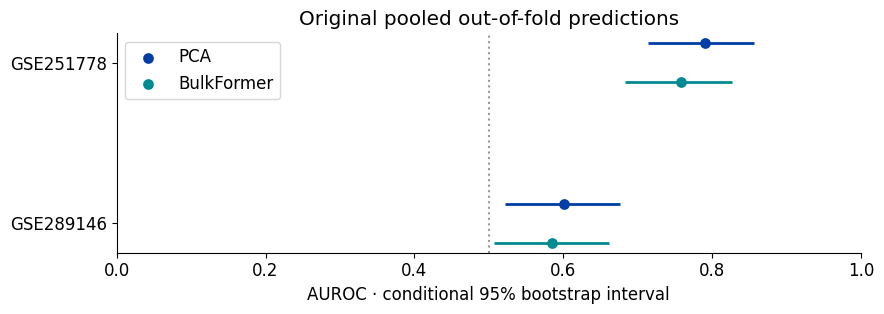

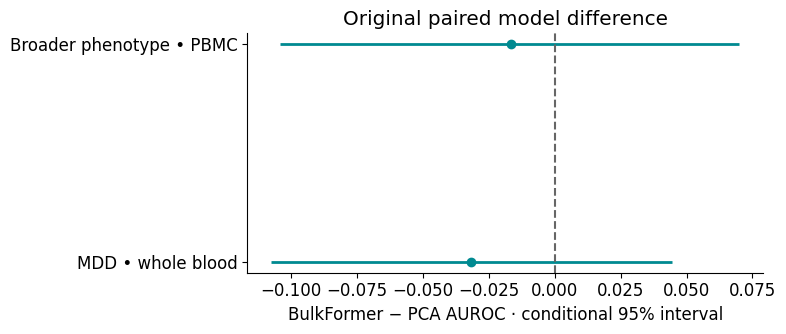

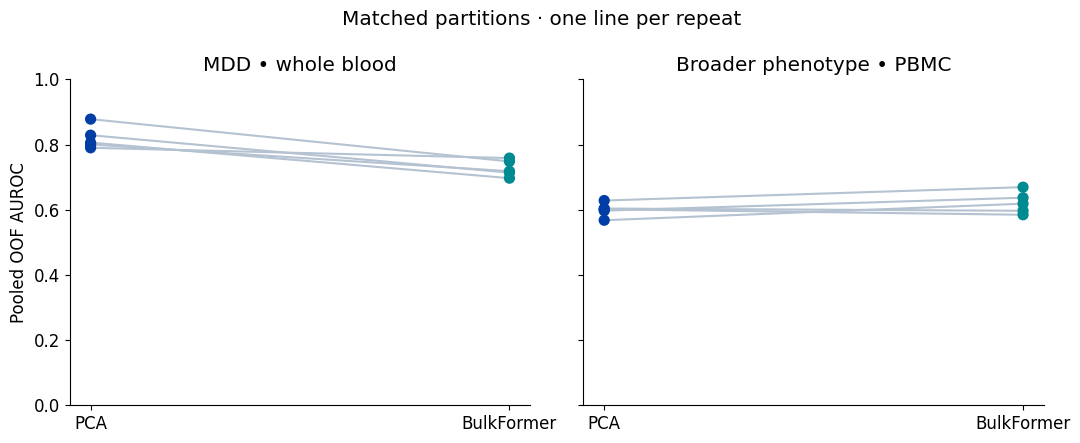

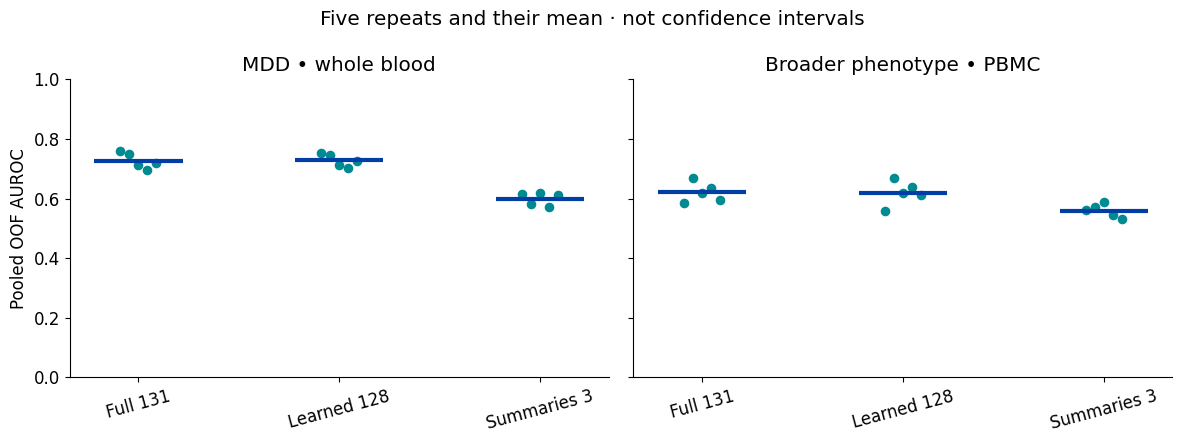

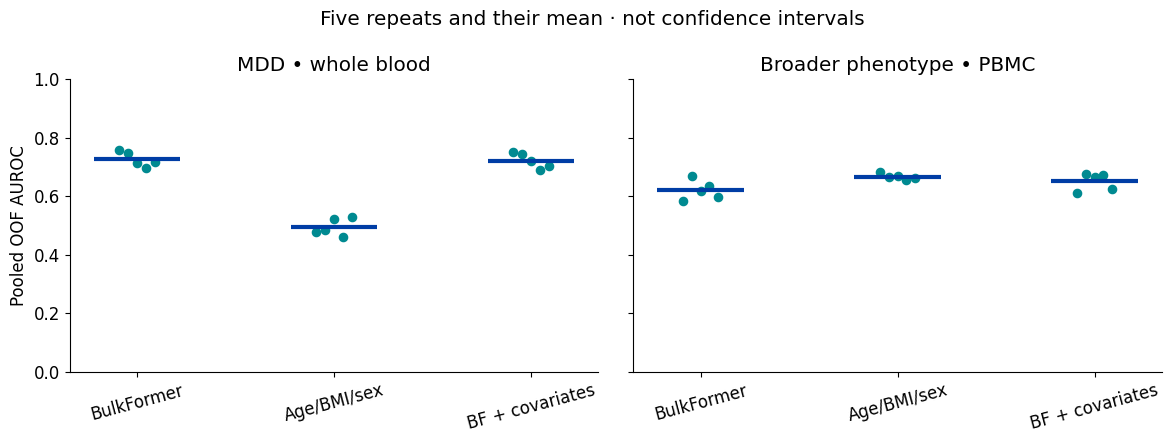

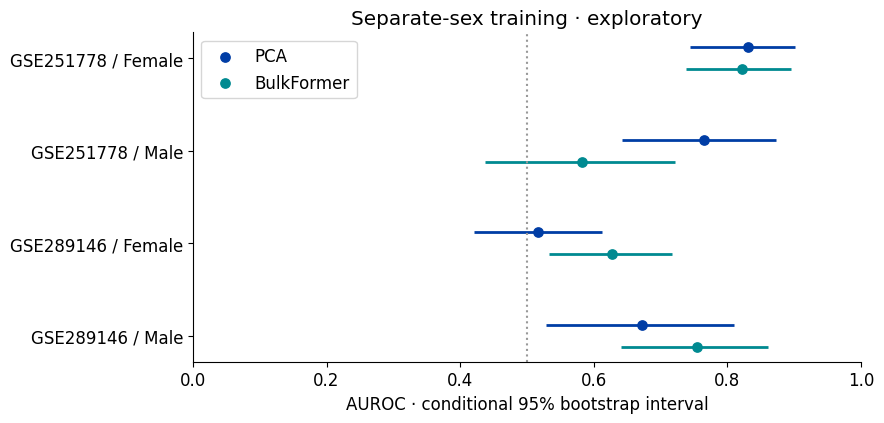

Figures: /content/BulkFormer_Poster_Additional_Analyses/results/figures


In [ ]:
COLORS={'PCA':'#003DA5','BulkFormer':'#008A91'}
NAMES={'GSE251778':'MDD • whole blood','GSE289146':'Broader phenotype • PBMC'}
def save_plot(fig,name):
    fig.tight_layout()
    for extension in ['png','pdf']:fig.savefig(FIGURES/f'{name}.{extension}',bbox_inches='tight')
    plt.show();plt.close(fig)
def interval_plot(table,group_columns,name,title):
    groups=list(table.groupby(group_columns,sort=False))
    fig,ax=plt.subplots(figsize=(9,max(3.3,len(groups)*1.1)))
    for i,(key,part) in enumerate(groups):
        for method,offset in [('PCA',-.12),('BulkFormer',.12)]:
            r=part.loc[part.comparison==method].iloc[0]
            ax.hlines(i+offset,r.lower95,r.upper95,color=COLORS[method],lw=2)
            ax.scatter(r.estimate,i+offset,color=COLORS[method],s=45,label=method if i==0 else None)
    labels=[' / '.join(map(str,key)) if isinstance(key,tuple) else str(key) for key,_ in groups]
    ax.set_yticks(range(len(groups)),labels);ax.invert_yaxis();ax.axvline(.5,color='.6',ls=':')
    ax.set_xlim(0,1);ax.set_xlabel('AUROC · conditional 95% bootstrap interval');ax.set_title(title)
    ax.legend(loc='best');save_plot(fig,name)
interval_plot(original_intervals,['cohort'],'original_auroc_intervals','Original pooled out-of-fold predictions')
fig,ax=plt.subplots(figsize=(8,3.5))
for i,cohort in enumerate(original):
    r=original_intervals.query('cohort==@cohort and comparison=="BF_minus_PCA"').iloc[0]
    ax.hlines(i,r.lower95,r.upper95,color=COLORS['BulkFormer'],lw=2);ax.scatter(r.estimate,i,color=COLORS['BulkFormer'])
ax.set_yticks([0,1],[NAMES[c] for c in original]);ax.axvline(0,color='.4',ls='--')
ax.set_xlabel('BulkFormer − PCA AUROC · conditional 95% interval');ax.set_title('Original paired model difference')
save_plot(fig,'original_paired_difference')
if RUN_FULL_ANALYSES:
    fig,axes=plt.subplots(1,2,figsize=(11,4.5),sharey=True)
    for ax,(cohort,title) in zip(axes,NAMES.items()):
        w=repeat_scores.query('cohort==@cohort').pivot(index='seed',columns='method',values='AUROC')
        for _,row in w.iterrows():
            ax.plot([0,1],[row.PCA,row.full131],color='#B5C2D2',zorder=1)
            ax.scatter([0,1],[row.PCA,row.full131],c=[COLORS['PCA'],COLORS['BulkFormer']],s=50,zorder=2)
        ax.set_xticks([0,1],['PCA','BulkFormer']);ax.set_title(title);ax.set_ylim(0,1)
    axes[0].set_ylabel('Pooled OOF AUROC');fig.suptitle('Matched partitions · one line per repeat')
    save_plot(fig,'paired_repeats')
    for family,methods,labels in [
        ('feature_ablation',['full131','learned128','summaries3'],['Full 131','Learned 128','Summaries 3']),
        ('covariates',['full131','age_BMI_sex','BF_plus_age_BMI_sex'],['BulkFormer','Age/BMI/sex','BF + covariates'])]:
        fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
        for ax,(cohort,title) in zip(axes,NAMES.items()):
            for j,method in enumerate(methods):
                values=repeat_scores.query('cohort==@cohort and method==@method').sort_values('seed').AUROC.to_numpy()
                ax.scatter(j+np.linspace(-.09,.09,len(values)),values,color=COLORS['BulkFormer'],s=35)
                ax.hlines(values.mean(),j-.22,j+.22,color=COLORS['PCA'],lw=3)
            ax.set_xticks(range(len(methods)),labels,rotation=15);ax.set_ylim(0,1);ax.set_title(title)
        axes[0].set_ylabel('Pooled OOF AUROC');fig.suptitle('Five repeats and their mean · not confidence intervals')
        save_plot(fig,family)
    interval_plot(sex_intervals,['cohort','sex'],'separate_sex_intervals','Separate-sex training · exploratory')
print('Figures:',FIGURES)


## 11. Export

This cell creates a local results archive containing participant-level predictions and embeddings as well as aggregate tables and figures. Keep that archive private pending faculty review. It is not the public repository upload package. The saved export log below comes from the original run; browser download scripts have been removed from the public copy.


In [ ]:
import shutil
manifest={
    'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),
    'analysis_status':'new_reconstruction_not_exact_replay_of_additional_document',
    'full_analysis':RUN_FULL_ANALYSES,'repeat_seeds':REPEAT_SEEDS,
    'outer_folds':5,'inner_folds':4,'sex_outer_folds':4,'sex_inner_folds':3,
    'C_values':C_VALUES,'PCA_rule':'90% training variance; component count not grid-tuned',
    'bootstrap':{'draws':N_BOOTSTRAP,'seed':BOOTSTRAP_SEED,'method':'paired class-stratified percentile; fixed OOF predictions'},
    'MDD_extended_covariates_reconstructed':MDD_EXTENDED_COVARIATES,
    'original_archive_sha256':ORIGINAL_ARCHIVE_SHA256,'bulkformer_commit':BF_COMMIT,'mdd_commit':MDD_COMMIT,
    'embeddings':'original saved 131-feature mean embeddings; no neural-model rerun',
    'versions':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','rdata','matplotlib']},
    'python':platform.python_version()}
(RESULTS/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2))
for cohort,item in original.items():
    item['predictions'].to_csv(RESULTS/f'{cohort}_original_oof_predictions.csv',index=False)
    np.save(RESULTS/f'{cohort}_original_embeddings.npy',item['embeddings'])
(RESULTS/'READ_ME.txt').write_text(
    'NEW reconstructed analysis. See analysis_manifest.json for exact settings.\n'
    'Historical reference values are transcribed, not newly computed.\n'
    'Bootstrap intervals condition on fixed OOF predictions; they omit model-training uncertainty.\n'
    'Repeat ranges are not confidence intervals. Sex analyses are exploratory.\n'
    'GSE289146 is a broader psychiatric phenotype, not a second MDD case-control cohort.\n'
    'The MDD 1000-bp missing-length fallback is preserved from the original notebook and needs review.\n')
archive_path=shutil.make_archive(str(ROOT/'BulkFormer_Additional_Analyses_Results'),'zip',RESULTS)
print('Saved:',archive_path)
print('Original bootstrap and pooled subgroup tables are available even in quick mode.')
try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print('Outside Colab: open the ZIP at the path above.')


Saved: /content/BulkFormer_Poster_Additional_Analyses/BulkFormer_Additional_Analyses_Results.zip
Original bootstrap and pooled subgroup tables are available even in quick mode.
